In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
#load dataset
housing = fetch_california_housing()

data = pd.DataFrame(housing.data, columns=housing.feature_names)
data["Price"] = housing.target

In [ ]:
#select the feature
x = data[['AveRooms']].values
y = data["Price"].values

In [ ]:
#split data
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size = 0.2, random_state = 42
)

In [22]:
#feature scaling
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [23]:
w=0
b=0
learning_rate = 0.01
epochs = 1000

n = len(x_train_scaled)

for i in range(epochs):

    y_pred = w * x_train_scaled.flatten() + b

    dw = (1/n) * np.sum((y_pred - y_train) * x_train_scaled.flatten())
    db = (1/n) * np.sum(y_pred - y_train)

    w = w - learning_rate * dw
    b = b - learning_rate * db

    if i % 100 == 0:
        cost = (1/(2*n)) * np.sum((y_pred - y_train) ** 2)
        print(f"Epoch {i}, Cost = {cost:.4f}")

y_pred_gd = w * x_test_scaled.flatten() + b

Epoch 0, Cost = 2.8149
Epoch 100, Cost = 0.9414
Epoch 200, Cost = 0.6904
Epoch 300, Cost = 0.6568
Epoch 400, Cost = 0.6523
Epoch 500, Cost = 0.6517
Epoch 600, Cost = 0.6516
Epoch 700, Cost = 0.6516
Epoch 800, Cost = 0.6516
Epoch 900, Cost = 0.6516


In [9]:
print("Gradient Descent")
print("----------------")
print("Weight:",w)
print("Bias:",b)
print("MSE:", mean_squared_error(y_test,y_pred_gd))
print("R2 score:", r2_score(y_test, y_pred_gd))

Gradient Descent
----------------
Weight: 0.18323090648660517
Bias: 2.0718574888450205
MSE: 1.292327655590046
R2 score: 0.013798228607320828


In [14]:
#Normal equation

x_train_ne = np.c_[np.ones((len(x_train),1)), x_train]
x_test_ne = np.c_[np.ones((len(x_test),1)), x_test]

theta = np.linalg.inv(x_train_ne.T @ x_train_ne) @ x_train_ne.T @ y_train

y_pred_ne = x_test_ne @ theta

In [15]:
print("\nNormal Equation")
print("----------------")
print("Bias:", theta[0])
print("Weight:", theta[1])
print("MSE:", mean_squared_error(y_test, y_pred_ne))
print("R2 Score:", r2_score(y_test, y_pred_ne))


Normal Equation
----------------
Bias: 1.6547622685968417
Weight: 0.07675558963126736
MSE: 1.2923314440807299
R2 Score: 0.013795337532284901


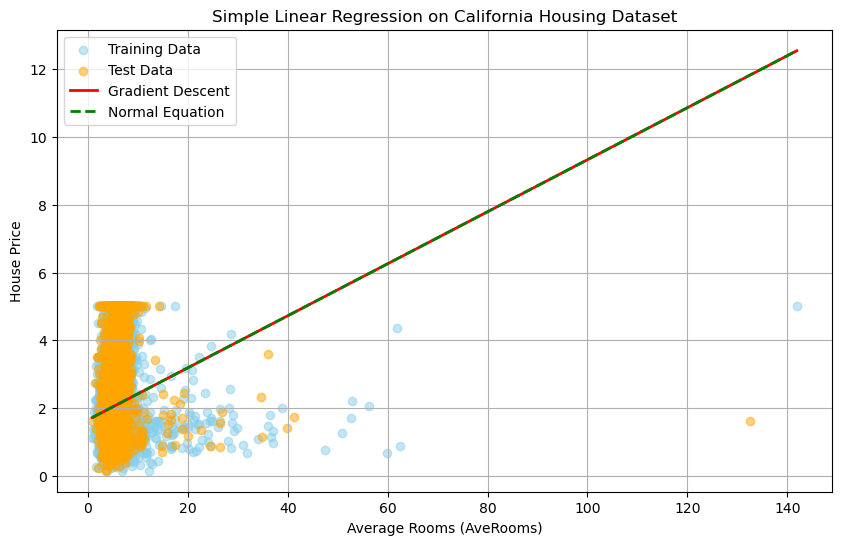

In [21]:

w_original = w / scaler.scale_[0]
b_original = b - (w * scaler.mean_[0] / scaler.scale_[0])


x_line = np.linspace(x.min(), x.max(), 100).reshape(-1, 1)


y_line_gd = w_original * x_line.flatten() + b_original
y_line_ne = theta[0] + theta[1] * x_line.flatten()


plt.figure(figsize=(10, 6))

# Scatter plot of data
plt.scatter(x_train, y_train, color='skyblue', alpha=0.5, label='Training Data')
plt.scatter(x_test, y_test, color='orange', alpha=0.5, label='Test Data')

# Regression lines
plt.plot(x_line, y_line_gd, color='red', linewidth=2, label='Gradient Descent')
plt.plot(x_line, y_line_ne, color='green', linestyle='--', linewidth=2,
         label='Normal Equation')

plt.xlabel("Average Rooms (AveRooms)")
plt.ylabel("House Price")
plt.title("Simple Linear Regression on California Housing Dataset")
plt.legend()
plt.grid(True)

plt.show()